# Demo Vision Transformer (ViT) với PyTorch + `timm`

Notebook đi kèm slide **"Tìm hiểu kiến trúc Vision Transformer (ViT) và ứng dụng trong Thị giác máy tính"**.

**Mô hình dùng trong demo**

| Vai trò | Tên trong `timm` | Trọng số |
|---|---|---|
| Mô hình chính | `vit_base_patch16_224.augreg2_in21k_ft_in1k` | **Pre-trained**: huấn luyện trước trên ImageNet-21k, fine-tune trên ImageNet-1k |
| Đối chứng | cùng kiến trúc, `pretrained=False` | **Khởi tạo ngẫu nhiên** (chưa huấn luyện) |
| So sánh attention | `vit_small_patch16_224.dino` | Pre-trained tự giám sát DINO trên ImageNet-1k (không nhãn) |
| So sánh CNN | `resnet50.a1_in1k` | Pre-trained trên ImageNet-1k |


## 0. Cấu hình

In [1]:
# Bỏ comment dòng dưới nếu chạy trên Colab hoặc máy chưa có thư viện
# !pip install -q timm matplotlib pandas pillow

import os, json, math, time, random, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import timm
from timm.data import ImageNetInfo, resolve_data_config
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

warnings.filterwarnings("ignore")
torch.set_grad_enabled(False)          # chỉ suy luận, không huấn luyện
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Đường dẫn: notebook nằm trong thư mục notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG_DIR = ROOT / "data" / "images"
FIG_DIR = ROOT / "outputs" / "figures"
MET_DIR = ROOT / "outputs" / "metrics"
for d in (IMG_DIR, FIG_DIR, MET_DIR):
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.titlesize": 11})
SUMMARY = {}                            # gom số liệu chính, lưu ra summary.json ở cuối


def save_fig(fig, name):
    # Lưu hình vào outputs/figures
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print("Đã lưu:", (FIG_DIR / name).relative_to(ROOT))


def save_table(df, name):
    # Lưu bảng vào outputs/metrics
    df.to_csv(MET_DIR / name, index=False, encoding="utf-8-sig")
    print("Đã lưu:", (MET_DIR / name).relative_to(ROOT))


print("torch", torch.__version__, "| timm", timm.__version__, "| device:", DEVICE)

c:\Users\CA\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\CA\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\jit\_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


torch 2.14.1+cpu | timm 1.0.22 | device: cpu


### Ảnh mẫu
Ảnh lấy từ tập COCO val2017 (giấy phép CC BY 4.0). Nếu chưa có trong `data/images` thì tự tải về.

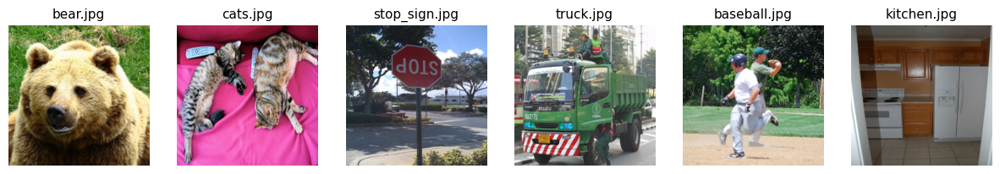

In [2]:
IMAGES = {
    "bear.jpg":      "http://images.cocodataset.org/val2017/000000000285.jpg",
    "cats.jpg":      "http://images.cocodataset.org/val2017/000000039769.jpg",
    "stop_sign.jpg": "http://images.cocodataset.org/val2017/000000000724.jpg",
    "truck.jpg":     "http://images.cocodataset.org/val2017/000000018837.jpg",
    "baseball.jpg":  "http://images.cocodataset.org/val2017/000000000872.jpg",
    "kitchen.jpg":   "http://images.cocodataset.org/val2017/000000000802.jpg",
}
for name, url in IMAGES.items():
    if not (IMG_DIR / name).exists():
        urllib.request.urlretrieve(url, IMG_DIR / name)

IMG_SIZE = 224
def load_image(name):
    # Resize thẳng về 224x224 (không crop) để attention map phủ toàn ảnh
    return Image.open(IMG_DIR / name).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)

imgs = {n: load_image(n) for n in IMAGES}
fig, axes = plt.subplots(1, len(imgs), figsize=(15, 2.8))
for ax, (n, im) in zip(axes, imgs.items()):
    ax.imshow(im); ax.set_title(n); ax.axis("off")
plt.show()

### Tải mô hình ViT-B/16 (pre-trained)

`vit_base_patch16_224.augreg2_in21k_ft_in1k`: ViT-Base, patch 16×16, ảnh 224×224.
Trọng số **đã huấn luyện sẵn** (ImageNet-21k → fine-tune ImageNet-1k), theo Steiner et al. (2021) *"How to train your ViT?"*.

In [3]:
MODEL_NAME = "vit_base_patch16_224.augreg2_in21k_ft_in1k"
model = timm.create_model(MODEL_NAME, pretrained=True).eval().to(DEVICE)

# Chuẩn hoá ảnh theo cấu hình của chính mô hình
cfg = resolve_data_config({}, model=model)
normalize = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize(cfg["mean"], cfg["std"])])
def to_input(img):
    return normalize(img).unsqueeze(0).to(DEVICE)      # (1, 3, 224, 224)

labels = ImageNetInfo()                                  # tên 1000 lớp ImageNet
def label(i):
    return labels.index_to_description(int(i))

P = model.patch_embed.patch_size[0]                      # kích thước patch
D = model.embed_dim                                      # chiều embedding
L = len(model.blocks)                                    # số khối encoder
H = model.blocks[0].attn.num_heads                       # số head
N = (IMG_SIZE // P) ** 2                                 # số patch
n_params = sum(p.numel() for p in model.parameters())
print(f"Trọng số: PRE-TRAINED | patch={P} | D={D} | L={L} | heads={H} | N={N} | params={n_params/1e6:.2f}M")
print("mean/std chuẩn hoá:", cfg["mean"], cfg["std"])
SUMMARY.update(model=MODEL_NAME, weights="pretrained (IN-21k -> IN-1k)", patch=P, dim=D,
               depth=L, heads=H, num_patches=N, params_M=round(n_params / 1e6, 2))

Trọng số: PRE-TRAINED | patch=16 | D=768 | L=12 | heads=12 | N=196 | params=86.57M
mean/std chuẩn hoá: (0.5, 0.5, 0.5) (0.5, 0.5, 0.5)


### Hàm lấy attention của từng khối

`timm` dùng attention hợp nhất (fused) nên không trả ma trận attention. Hàm dưới đây lấy đầu vào đã qua `LayerNorm` của mỗi khối rồi **tính lại** $A = \mathrm{softmax}(QK^\top/\sqrt{d_k})$ từ chính trọng số `qkv` của khối đó.

In [4]:
def attention_weights(attn, xn):
    # attn: module Attention của 1 block; xn: đầu vào đã LayerNorm, shape (B, N, D)
    B, Nt, C = xn.shape
    h, d = attn.num_heads, C // attn.num_heads
    qkv = attn.qkv(xn).reshape(B, Nt, 3, h, d).permute(2, 0, 3, 1, 4)   # (3, B, h, N, d)
    q, k, v = qkv[0], qkv[1], qkv[2]
    scores = q @ k.transpose(-2, -1) / math.sqrt(d)                     # (B, h, N, N)
    return scores.softmax(dim=-1)


def get_attentions(m, x):
    # Chạy forward 1 lần, trả về logits và list attention (B, h, N, N) của mọi block
    feats = []
    hooks = [blk.norm1.register_forward_hook(lambda mod, i, o: feats.append(o)) for blk in m.blocks]
    out = m(x)
    for hk in hooks:
        hk.remove()
    attns = [attention_weights(blk.attn, f) for blk, f in zip(m.blocks, feats)]
    return out, attns


def to_map(v, size=IMG_SIZE):
    # vector 196 phần tử -> ảnh 224x224 (nội suy) để đè lên ảnh gốc
    g = int(math.sqrt(v.numel()))
    m = v.reshape(1, 1, g, g)
    m = F.interpolate(m, size=(size, size), mode="bilinear", align_corners=False)[0, 0]
    m = (m - m.min()) / (m.max() - m.min() + 1e-8)
    return m.cpu().numpy()


# Tính attention cho toàn bộ ảnh mẫu (dùng lại ở nhiều mục)
ATT, LOGITS = {}, {}
for n, im in imgs.items():
    LOGITS[n], ATT[n] = get_attentions(model, to_input(im))
print("Số block:", len(ATT["bear.jpg"]), "| shape attention 1 block:", tuple(ATT["bear.jpg"][0].shape))

Số block: 12 | shape attention 1 block: (1, 12, 197, 197)


## 1. Đặt vấn đề: receptive field của CNN và attention toàn cục của ViT

- CNN với kernel 3×3, stride 1: mỗi lớp chỉ nhìn 3×3 điểm lân cận, receptive field sau $l$ lớp là $(2l+1)\times(2l+1)$ pixel. Muốn nối hai vùng xa nhau phải xếp nhiều lớp (hoặc dùng pooling/stride).
- ViT: ngay ở **khối đầu tiên**, mỗi patch đã tính attention với **tất cả** 196 patch còn lại.

Hình dưới: bên trái là receptive field lý thuyết của CNN 3×3 sau 1, 5, 20 lớp; bên phải là attention thực tế của 1 patch (ô đỏ) ở **block 1** của ViT-B/16 pre-trained (head có khoảng cách attention lớn nhất).

Đã lưu: outputs\figures\01_receptive_field_vs_global_attention.png


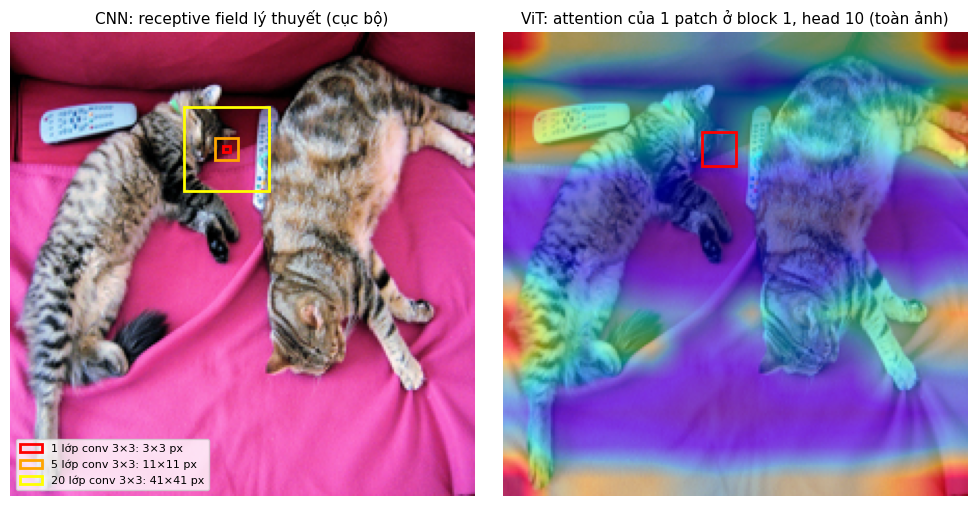

In [5]:
name = "cats.jpg"
q_rc = (3, 6)                                   # patch truy vấn: (hàng, cột) trên lưới 14x14
q_idx = 1 + q_rc[0] * 14 + q_rc[1]              # +1 vì token 0 là [CLS]

# Chọn head ở block 1 có khoảng cách attention trung bình lớn nhất
A0 = ATT[name][0][0, :, 1:, 1:]                  # (h, 196, 196), bỏ [CLS]
A0 = A0 / A0.sum(-1, keepdim=True)
coords = torch.stack(torch.meshgrid(torch.arange(14), torch.arange(14), indexing="ij"), -1).reshape(-1, 2).float()
dist = torch.cdist(coords, coords) * P           # khoảng cách giữa các patch (pixel)
head = int((A0 * dist).sum(-1).mean(-1).argmax())

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(imgs[name])
cy, cx = q_rc[0] * P + P // 2, q_rc[1] * P + P // 2
for layers, col in [(1, "red"), (5, "orange"), (20, "yellow")]:
    r = 2 * layers + 1
    ax[0].add_patch(mpatches.Rectangle((cx - r / 2, cy - r / 2), r, r, fill=False, ec=col, lw=2,
                                       label=f"{layers} lớp conv 3×3: {r}×{r} px"))
ax[0].legend(loc="lower left", fontsize=8); ax[0].set_title("CNN: receptive field lý thuyết (cục bộ)")
ax[0].axis("off")

att_q = ATT[name][0][0, head, q_idx, 1:]
ax[1].imshow(imgs[name]); ax[1].imshow(to_map(att_q), cmap="jet", alpha=0.5)
ax[1].add_patch(mpatches.Rectangle((q_rc[1] * P, q_rc[0] * P), P, P, fill=False, ec="red", lw=2))
ax[1].set_title(f"ViT: attention của 1 patch ở block 1, head {head} (toàn ảnh)")
ax[1].axis("off")
plt.tight_layout(); save_fig(fig, "01_receptive_field_vs_global_attention.png"); plt.show()

## 2. Kiến trúc tổng quan và số tham số

ViT = Patch Embedding → thêm `[CLS]` + Positional Embedding → $L$ khối Transformer Encoder → LayerNorm → MLP Head (ở bản fine-tune là 1 lớp Linear).
Bảng dưới đếm tham số trực tiếp từ mô hình.

In [6]:
blk = model.blocks[0]
count = lambda m: sum(p.numel() for p in m.parameters())
rows = [
    ("Patch embedding (Conv 16x16 = Linear 768->768)", count(model.patch_embed)),
    ("[CLS] token", model.cls_token.numel()),
    ("Positional embedding (197 x 768)", model.pos_embed.numel()),
    ("1 block: LayerNorm x2", count(blk.norm1) + count(blk.norm2)),
    ("1 block: MSA (qkv + proj)", count(blk.attn)),
    ("1 block: MLP (768->3072->768)", count(blk.mlp)),
    (f"{L} blocks Encoder", count(model.blocks)),
    ("LayerNorm cuối", count(model.norm)),
    ("MLP Head (768 -> 1000)", count(model.head)),
    ("Tổng", n_params),
]
df_params = pd.DataFrame(rows, columns=["Thành phần", "Số tham số"])
save_table(df_params, "params_breakdown.csv")
df_params.style.format({"Số tham số": "{:,}"})

Đã lưu: outputs\metrics\params_breakdown.csv


,Thành phần,Số tham số
0,Patch embedding (Conv 16x16 = Linear 768->768),"590,592"
1,[CLS] token,768
2,Positional embedding (197 x 768),"151,296"
3,1 block: LayerNorm x2,"3,072"
4,1 block: MSA (qkv + proj),"2,362,368"
5,1 block: MLP (768->3072->768),"4,722,432"
6,12 blocks Encoder,"85,054,464"
7,LayerNorm cuối,"1,536"
8,MLP Head (768 -> 1000),"769,000"
9,Tổng,"86,567,656"


In [7]:
print(model.blocks[0])      # cấu trúc 1 khối encoder trong timm

Block(
  (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
  (attn): Attention(
    (qkv): Linear(in_features=768, out_features=2304, bias=True)
    (q_norm): Identity()
    (k_norm): Identity()
    (attn_drop): Dropout(p=0.0, inplace=False)
    (norm): Identity()
    (proj): Linear(in_features=768, out_features=768, bias=True)
    (proj_drop): Dropout(p=0.0, inplace=False)
  )
  (ls1): Identity()
  (drop_path1): Identity()
  (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
  (mlp): Mlp(
    (fc1): Linear(in_features=768, out_features=3072, bias=True)
    (act): GELU(approximate='none')
    (drop1): Dropout(p=0.0, inplace=False)
    (norm): Identity()
    (fc2): Linear(in_features=3072, out_features=768, bias=True)
    (drop2): Dropout(p=0.0, inplace=False)
  )
  (ls2): Identity()
  (drop_path2): Identity()
)


## 3. Biểu diễn đầu vào: Patch + `[CLS]` + Position

Công thức (Dosovitskiy et al., 2020, Eq. 1):

$$\mathbf{z}_0 = [\mathbf{x}_{class};\ \mathbf{x}_p^1\mathbf{E};\ \mathbf{x}_p^2\mathbf{E};\ \dots;\ \mathbf{x}_p^N\mathbf{E}] + \mathbf{E}_{pos},\quad \mathbf{E}\in\mathbb{R}^{(P^2 C)\times D},\ \mathbf{E}_{pos}\in\mathbb{R}^{(N+1)\times D}$$

Với $H=W=224$, $P=16$, $C=3$: $N = HW/P^2 = 196$, mỗi patch làm phẳng có $P^2C = 768$ giá trị.

Dưới đây làm **từng bước bằng tay** rồi so sánh với kết quả của `timm`.

In [8]:
x = to_input(imgs["bear.jpg"])                                   # (1, 3, 224, 224)
shapes = [("Ảnh đầu vào", tuple(x.shape), "B, C, H, W")]

# Bước 1: cắt ảnh thành lưới 14x14 patch, mỗi patch 3x16x16
p = x.unfold(2, P, P).unfold(3, P, P)                             # (1, 3, 14, 14, 16, 16)
shapes.append(("Cắt patch (unfold)", tuple(p.shape), "B, C, 14, 14, P, P"))

# Bước 2: làm phẳng mỗi patch thành vector 768 = 16*16*3
p = p.permute(0, 2, 3, 1, 4, 5).reshape(1, N, -1)                 # (1, 196, 768)
shapes.append(("Làm phẳng (flatten)", tuple(p.shape), "B, N, P*P*C"))

# Bước 3: chiếu tuyến tính x_p E + b (dùng đúng trọng số Conv2d của timm)
W_e = model.patch_embed.proj.weight.reshape(D, -1)                # (768, 768)
b_e = model.patch_embed.proj.bias
tok = p @ W_e.T + b_e                                             # (1, 196, 768)
shapes.append(("Linear projection (E)", tuple(tok.shape), "B, N, D"))
print("Sai khác so với timm patch_embed:", (tok - model.patch_embed(x)).abs().max().item())

# Bước 4: thêm [CLS] token vào đầu chuỗi
cls = model.cls_token.expand(1, -1, -1)                           # (1, 1, 768)
z0 = torch.cat([cls, tok], dim=1)                                 # (1, 197, 768)
shapes.append(("Nối [CLS] token", tuple(z0.shape), "B, N+1, D"))

# Bước 5: cộng positional embedding (học được, 1D)
z0 = z0 + model.pos_embed                                         # (1, 197, 768)
shapes.append(("+ Positional embedding", tuple(z0.shape), "B, N+1, D"))

# Bước 6: qua L khối encoder, kích thước không đổi
zL = model.blocks(z0)
shapes.append((f"Sau {L} khối Encoder", tuple(zL.shape), "B, N+1, D"))
zL = model.norm(zL)
y_cls = zL[:, 0]                                                  # lấy vector của [CLS]
shapes.append(("Lấy z_L^0 ([CLS]) sau LayerNorm", tuple(y_cls.shape), "B, D"))
logits = model.head(y_cls)
shapes.append(("MLP Head", tuple(logits.shape), "B, số lớp"))
print("Sai khác logits so với model(x):", (logits - model(x)).abs().max().item())

df_shapes = pd.DataFrame(shapes, columns=["Bước", "Shape", "Ý nghĩa"])
df_shapes["Shape"] = df_shapes["Shape"].astype(str)
save_table(df_shapes, "tensor_shapes.csv")
df_shapes

Sai khác so với timm patch_embed: 4.291534423828125e-06
Sai khác logits so với model(x): 2.0265579223632812e-06
Đã lưu: outputs\metrics\tensor_shapes.csv


,Bước,Shape,Ý nghĩa
0,Ảnh đầu vào,"(1, 3, 224, 224)","B, C, H, W"
1,Cắt patch (unfold),"(1, 3, 14, 14, 16, 16)","B, C, 14, 14, P, P"
2,Làm phẳng (flatten),"(1, 196, 768)","B, N, P*P*C"
3,Linear projection (E),"(1, 196, 768)","B, N, D"
4,Nối [CLS] token,"(1, 197, 768)","B, N+1, D"
5,+ Positional embedding,"(1, 197, 768)","B, N+1, D"
6,Sau 12 khối Encoder,"(1, 197, 768)","B, N+1, D"
7,Lấy z_L^0 ([CLS]) sau LayerNorm,"(1, 768)","B, D"
8,MLP Head,"(1, 1000)","B, số lớp"


Hình minh họa: ảnh 224×224 → lưới 14×14 patch → chuỗi 196 vector (+1 `[CLS]`) → ma trận $\mathbf{z}_0$ kích thước 197×768.

Đã lưu: outputs\figures\03_patch_embedding.png


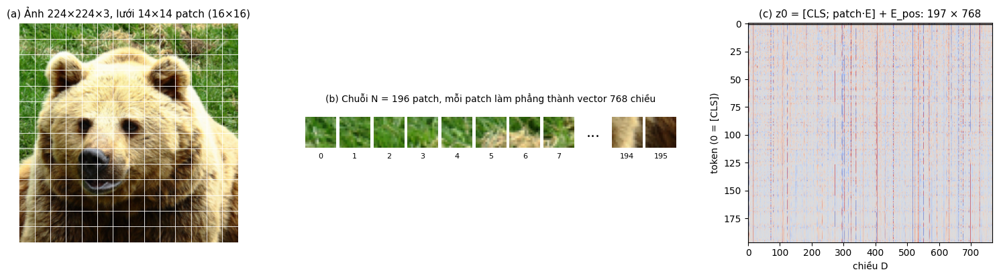

In [9]:
img = np.array(imgs["bear.jpg"])
fig = plt.figure(figsize=(15, 4.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1.6, 1])

# (a) ảnh với lưới patch
ax = fig.add_subplot(gs[0]); ax.imshow(img)
for i in range(0, IMG_SIZE + 1, P):
    ax.axhline(i - 0.5, c="w", lw=0.6); ax.axvline(i - 0.5, c="w", lw=0.6)
ax.set_title("(a) Ảnh 224×224×3, lưới 14×14 patch (16×16)"); ax.axis("off")

# (b) chuỗi patch: hiển thị 8 patch đầu và 2 patch cuối
ax = fig.add_subplot(gs[1]); ax.axis("off"); ax.set_xlim(0, 11.5); ax.set_ylim(0, 3)
show = list(range(8)) + [None, 194, 195]
for j, k in enumerate(show):
    if k is None:
        ax.text(j + 0.5, 1.5, "...", ha="center", va="center", fontsize=16); continue
    r, c = divmod(k, 14)
    ax.imshow(img[r*P:(r+1)*P, c*P:(c+1)*P], extent=(j + 0.05, j + 0.95, 1.05, 1.95))
    ax.text(j + 0.5, 0.75, str(k), ha="center", fontsize=8)
ax.text(5.5, 2.4, "(b) Chuỗi N = 196 patch, mỗi patch làm phẳng thành vector 768 chiều", ha="center")

# (c) ma trận z0 (197 x 768)
ax = fig.add_subplot(gs[2])
ax.imshow(z0[0].cpu().numpy(), aspect="auto", cmap="coolwarm", vmin=-2, vmax=2)
ax.axhline(0.5, c="k", lw=1)
ax.set_title("(c) z0 = [CLS; patch·E] + E_pos: 197 × 768"); ax.set_xlabel("chiều D"); ax.set_ylabel("token (0 = [CLS])")
plt.tight_layout(); save_fig(fig, "03_patch_embedding.png"); plt.show()

### Positional embedding đã học

Mỗi ô nhỏ trong hình là độ tương đồng cosine giữa embedding vị trí của 1 patch và của tất cả 196 patch khác (giống Hình 7 trong paper gốc).
Nếu mô hình học được cấu trúc 2D, các ô sẽ sáng ở gần vị trí của chính nó và theo cùng hàng/cột, dù $\mathbf{E}_{pos}$ chỉ là bảng 1D.

Đã lưu: outputs\figures\03_pos_embedding_similarity.png


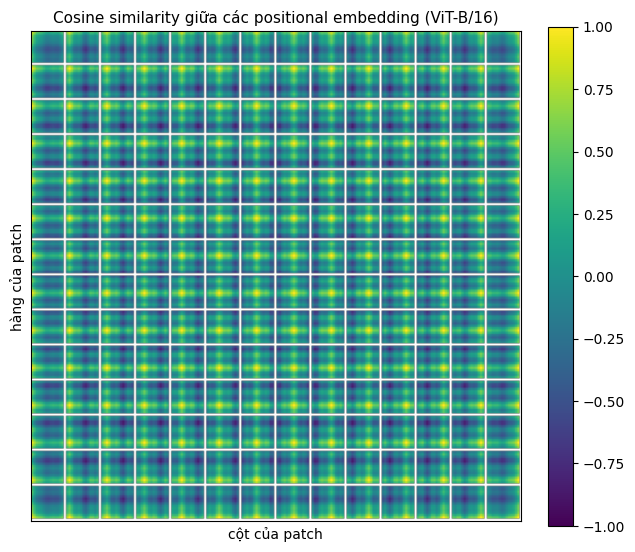

In [10]:
pos = model.pos_embed[0, 1:]                                   # (196, 768), bỏ [CLS]
pos = F.normalize(pos, dim=-1)
sim = (pos @ pos.T).reshape(14, 14, 14, 14).cpu().numpy()      # (hàng, cột, 14, 14)

canvas = np.full((14 * 15, 14 * 15), np.nan)
for r in range(14):
    for c in range(14):
        canvas[r*15:r*15+14, c*15:c*15+14] = sim[r, c]
fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(canvas, cmap="viridis", vmin=-1, vmax=1)
ax.set_title("Cosine similarity giữa các positional embedding (ViT-B/16)")
ax.set_xlabel("cột của patch"); ax.set_ylabel("hàng của patch"); ax.set_xticks([]); ax.set_yticks([])
plt.colorbar(im, ax=ax, fraction=0.046)
save_fig(fig, "03_pos_embedding_similarity.png"); plt.show()

## 4. Self-Attention tính tay trên 4 patch

$$Q = \mathbf{z}W_Q,\quad K = \mathbf{z}W_K,\quad V = \mathbf{z}W_V,\qquad \mathrm{Attention}(Q,K,V) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

- **Query** của patch $i$: patch $i$ đang "tìm" thông tin gì.
- **Key** của patch $j$: patch $j$ "có" thông tin gì để so khớp.
- **Value** của patch $j$: nội dung thực sự được lấy về nếu khớp.
- $A_{ij}$: tỷ lệ thông tin patch $i$ lấy từ patch $j$; mỗi hàng của $A$ có tổng bằng 1.

Ví dụ: chọn 4 patch trên ảnh hai con mèo, lấy $Q, K$ thật của **block 9** (ViT-B/16 pre-trained), chỉ tính softmax trên 4 patch này để dễ đọc (mô hình thật tính trên cả 197 token).

In [11]:
name, layer = "cats.jpg", 8                       # block 9 (đánh số từ 0 là 8)
picks = {"P1 đầu mèo trái": (3, 6), "P2 đầu mèo phải": (8, 10),
         "P3 thân mèo phải": (4, 10), "P4 chăn hồng": (12, 2)}
idx = [1 + r * 14 + c for r, c in picks.values()]

# Lấy đầu vào đã LayerNorm của block 9
feat = {}
hk = model.blocks[layer].norm1.register_forward_hook(lambda m, i, o: feat.update(x=o))
model(to_input(imgs[name])); hk.remove()

attn = model.blocks[layer].attn
d_k = D // H
qkv = attn.qkv(feat["x"]).reshape(1, N + 1, 3, H, d_k).permute(2, 0, 3, 1, 4)
q, k, v = qkv[0][0], qkv[1][0], qkv[2][0]           # mỗi cái (h, 197, 64)

# Điểm tương đồng giữa 4 patch, trung bình trên 12 head
S = (q[:, idx] @ k[:, idx].transpose(-2, -1)) / math.sqrt(d_k)    # (h, 4, 4)
A4 = S.softmax(-1).mean(0).cpu().numpy()                          # (4, 4)
names = list(picks)

print("Ví dụ head 0, cặp (P1, P2): q·k/sqrt(d) =", round(S[0, 0, 1].item(), 3))
df_a4 = pd.DataFrame(A4, index=names, columns=names).round(3)
save_table(df_a4.reset_index().rename(columns={"index": "Query \\ Key"}), "attention_4patches.csv")
df_a4

Ví dụ head 0, cặp (P1, P2): q·k/sqrt(d) = -1.793
Đã lưu: outputs\metrics\attention_4patches.csv


,P1 đầu mèo trái,P2 đầu mèo phải,P3 thân mèo phải,P4 chăn hồng
P1 đầu mèo trái,0.847,0.027,0.091,0.034
P2 đầu mèo phải,0.109,0.632,0.194,0.065
P3 thân mèo phải,0.123,0.233,0.609,0.035
P4 chăn hồng,0.079,0.059,0.026,0.837


Đã lưu: outputs\figures\04_attention_matrix_4patches.png


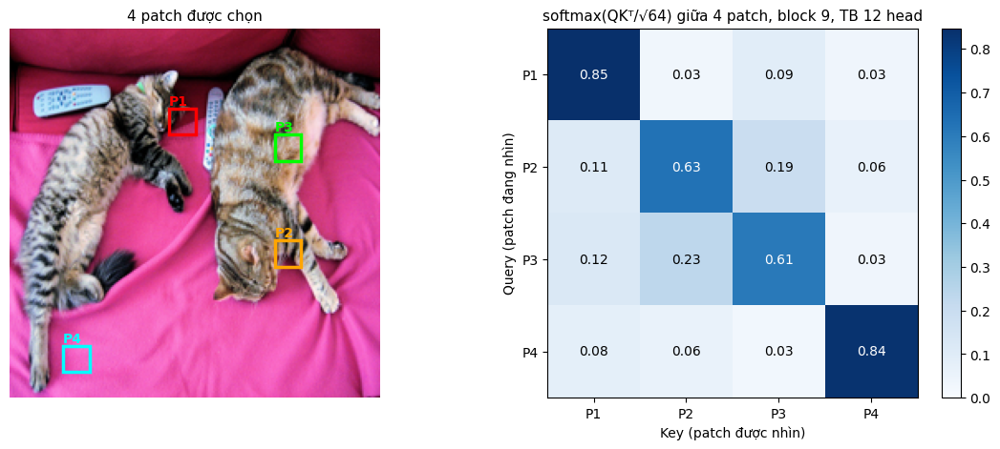

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
ax[0].imshow(imgs[name])
colors = ["red", "orange", "lime", "cyan"]
for (nm, (r, c)), col in zip(picks.items(), colors):
    ax[0].add_patch(mpatches.Rectangle((c * P, r * P), P, P, fill=False, ec=col, lw=2.5))
    ax[0].text(c * P, r * P - 2, nm.split()[0], color=col, fontsize=10, weight="bold")
ax[0].set_title("4 patch được chọn"); ax[0].axis("off")

im = ax[1].imshow(A4, cmap="Blues", vmin=0, vmax=A4.max())
for i in range(4):
    for j in range(4):
        ax[1].text(j, i, f"{A4[i, j]:.2f}", ha="center", va="center",
                   color="white" if A4[i, j] > A4.max() * 0.6 else "black")
short = [n.split()[0] for n in names]
ax[1].set_xticks(range(4), short); ax[1].set_yticks(range(4), short)
ax[1].set_xlabel("Key (patch được nhìn)"); ax[1].set_ylabel("Query (patch đang nhìn)")
ax[1].set_title(f"softmax(QKᵀ/√{d_k}) giữa 4 patch, block {layer + 1}, TB 12 head")
plt.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout(); save_fig(fig, "04_attention_matrix_4patches.png"); plt.show()

Kiểm tra: tính toàn bộ Self-Attention của block bằng tay và so với module `Attention` của `timm`.

In [13]:
A_full = (q @ k.transpose(-2, -1) / math.sqrt(d_k)).softmax(-1)   # (h, 197, 197)
out = (A_full @ v).transpose(0, 1).reshape(1, N + 1, D)            # nối các head
out = attn.proj(out)                                               # chiếu W_O
print("Tổng mỗi hàng của A (phải = 1):", A_full.sum(-1)[0, :3].tolist())
print("Sai khác tối đa so với timm:", (out - attn(feat["x"])).abs().max().item())

Tổng mỗi hàng của A (phải = 1): [1.0000001192092896, 1.0000001192092896, 1.0000001192092896]
Sai khác tối đa so với timm: 4.112720489501953e-06


## 5. Multi-Head Self-Attention (MSA)

$$\mathrm{MSA}(\mathbf{z}) = [\mathrm{head}_1;\dots;\mathrm{head}_h]\,W_O,\qquad \mathrm{head}_i = \mathrm{softmax}\!\left(\frac{Q_iK_i^\top}{\sqrt{d}}\right)V_i,\quad d = D/h$$

Với ViT-B: $D=768$, $h=12$, $d=64$. Theo dõi kích thước tensor qua từng bước:

In [14]:
xn = feat["x"]                                   # (B, N, D) = (1, 197, 768)
B_, N_, D_ = xn.shape
rows = [("Đầu vào (sau LayerNorm)", xn.shape)]
qkv = attn.qkv(xn);                                   rows.append(("Linear qkv: D -> 3D", qkv.shape))
qkv = qkv.reshape(B_, N_, 3, H, D_ // H);             rows.append(("Tách 3 x h head", qkv.shape))
qkv = qkv.permute(2, 0, 3, 1, 4);                     rows.append(("Đổi trục", qkv.shape))
q_, k_, v_ = qkv[0], qkv[1], qkv[2];                  rows.append(("Q (tương tự K, V)", q_.shape))
s_ = q_ @ k_.transpose(-2, -1) / math.sqrt(D_ // H);  rows.append(("QKᵀ/√d (attention score)", s_.shape))
a_ = s_.softmax(-1);                                  rows.append(("softmax theo hàng", a_.shape))
o_ = a_ @ v_;                                         rows.append(("A·V (mỗi head)", o_.shape))
o_ = o_.transpose(1, 2).reshape(B_, N_, D_);          rows.append(("Concat các head", o_.shape))
o_ = attn.proj(o_);                                   rows.append(("Linear W_O", o_.shape))

df_msa = pd.DataFrame([(a, str(tuple(b))) for a, b in rows], columns=["Bước", "Shape"])
save_table(df_msa, "msa_shapes.csv")
df_msa

Đã lưu: outputs\metrics\msa_shapes.csv


,Bước,Shape
0,Đầu vào (sau LayerNorm),"(1, 197, 768)"
1,Linear qkv: D -> 3D,"(1, 197, 2304)"
2,Tách 3 x h head,"(1, 197, 3, 12, 64)"
3,Đổi trục,"(3, 1, 12, 197, 64)"
4,"Q (tương tự K, V)","(1, 12, 197, 64)"
5,QKᵀ/√d (attention score),"(1, 12, 197, 197)"
6,softmax theo hàng,"(1, 12, 197, 197)"
7,A·V (mỗi head),"(1, 12, 197, 64)"
8,Concat các head,"(1, 197, 768)"
9,Linear W_O,"(1, 197, 768)"


### Mỗi head nhìn vào vùng khác nhau
Attention từ `[CLS]` tới 196 patch ở **block cuối**, vẽ riêng cho 12 head.

Đã lưu: outputs\figures\05_heads_last_layer.png


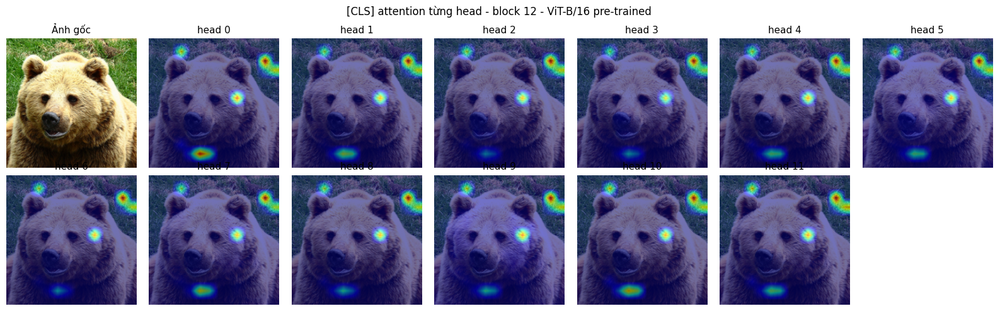

In [15]:
name = "bear.jpg"
A_last = ATT[name][-1][0, :, 0, 1:]                  # (12, 196): [CLS] -> patch
fig, axes = plt.subplots(2, 7, figsize=(16, 5))
axes = axes.ravel()
axes[0].imshow(imgs[name]); axes[0].set_title("Ảnh gốc"); axes[0].axis("off")
for hh in range(H):
    axes[hh + 1].imshow(imgs[name]); axes[hh + 1].imshow(to_map(A_last[hh]), cmap="jet", alpha=0.55)
    axes[hh + 1].set_title(f"head {hh}"); axes[hh + 1].axis("off")
axes[-1].axis("off")
plt.suptitle(f"[CLS] attention từng head - block {L} - ViT-B/16 pre-trained")
plt.tight_layout(); save_fig(fig, "05_heads_last_layer.png"); plt.show()

### Khoảng cách attention trung bình theo độ sâu

Với mỗi head: $\bar d = \frac{1}{N}\sum_i\sum_j A_{ij}\,\lVert pos_i - pos_j\rVert$ (pixel), trung bình trên 6 ảnh. Cách tính theo Hình 7 (phải) của paper gốc.
Head có $\bar d$ nhỏ hoạt động giống tích chập cục bộ; $\bar d$ lớn là nhìn toàn cục.

Đã lưu: outputs\metrics\attention_distance.csv
Đã lưu: outputs\figures\05_attention_distance.png


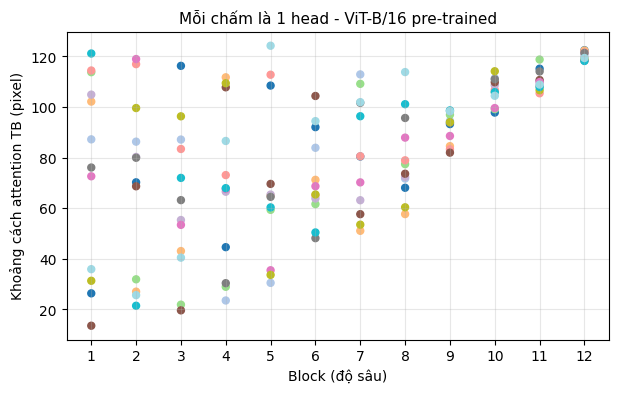

Block 1: min 13.6 px, max 121.2 px


In [16]:
rows = []
for li in range(L):
    for hh in range(H):
        vals = []
        for n in imgs:
            A = ATT[n][li][0, hh, 1:, 1:]
            A = A / A.sum(-1, keepdim=True)          # chuẩn hoá lại trên 196 patch
            vals.append((A * dist).sum(-1).mean().item())
        rows.append((li + 1, hh, float(np.mean(vals))))
df_dist = pd.DataFrame(rows, columns=["block", "head", "mean_distance_px"])
save_table(df_dist, "attention_distance.csv")

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df_dist["block"], df_dist["mean_distance_px"], c=df_dist["head"], cmap="tab20", s=25)
ax.set_xlabel("Block (độ sâu)"); ax.set_ylabel("Khoảng cách attention TB (pixel)")
ax.set_title("Mỗi chấm là 1 head - ViT-B/16 pre-trained"); ax.set_xticks(range(1, L + 1)); ax.grid(alpha=0.3)
save_fig(fig, "05_attention_distance.png"); plt.show()
b1 = df_dist[df_dist.block == 1].mean_distance_px
SUMMARY.update(attn_dist_block1_min=round(b1.min(), 1), attn_dist_block1_max=round(b1.max(), 1),
               attn_dist_last_mean=round(df_dist[df_dist.block == L].mean_distance_px.mean(), 1))
print("Block 1: min %.1f px, max %.1f px" % (b1.min(), b1.max()))

## 6. Khối ViT Encoder: Pre-Norm + Residual

$$\mathbf{z}'_\ell = \mathrm{MSA}(\mathrm{LN}(\mathbf{z}_{\ell-1})) + \mathbf{z}_{\ell-1},\qquad
\mathbf{z}_\ell = \mathrm{MLP}(\mathrm{LN}(\mathbf{z}'_\ell)) + \mathbf{z}'_\ell,\qquad
\mathbf{y} = \mathrm{LN}(\mathbf{z}_L^0)$$

MLP gồm 2 lớp Linear $768 \to 3072 \to 768$ với GELU ở giữa. Kiểm tra công thức trên bằng code:

In [17]:
blk = model.blocks[0]
z = z0                                              # (1, 197, 768) từ mục 3
z_mid = z + blk.attn(blk.norm1(z))                  # z'_l = MSA(LN(z)) + z
z_out = z_mid + blk.mlp(blk.norm2(z_mid))           # z_l  = MLP(LN(z')) + z'
print("Shape vào/ra:", tuple(z.shape), "->", tuple(z_out.shape))
print("Sai khác so với blk(z):", (z_out - blk(z)).abs().max().item())

Shape vào/ra: (1, 197, 768) -> (1, 197, 768)
Sai khác so với blk(z): 0.0


## 7. Phân loại ảnh (ViT-B/16 pre-trained)

Đã lưu: outputs\figures\07_classification_top3.png


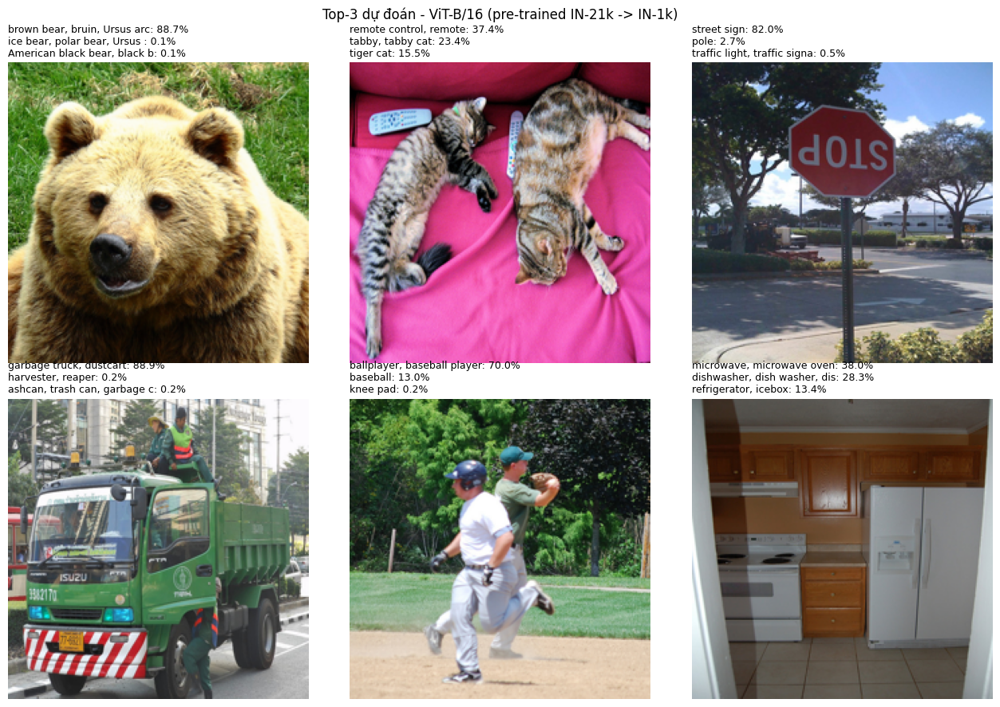

Đã lưu: outputs\metrics\predictions_top5.csv


,image,rank,label,prob
0,bear.jpg,1,"brown bear, bruin, Ursus arctos",0.8868
5,cats.jpg,1,"remote control, remote",0.3740
10,stop_sign.jpg,1,street sign,0.8195
15,truck.jpg,1,"garbage truck, dustcart",0.8889
20,baseball.jpg,1,"ballplayer, baseball player",0.6996
25,kitchen.jpg,1,"microwave, microwave oven",0.3798


In [18]:
rows = []
fig, axes = plt.subplots(2, 3, figsize=(13, 9))
for ax, n in zip(axes.ravel(), imgs):
    prob = LOGITS[n].softmax(-1)[0]
    top = prob.topk(5)
    for rank, (pv, iv) in enumerate(zip(top.values, top.indices), 1):
        rows.append((n, rank, label(iv), round(pv.item(), 4)))
    ax.imshow(imgs[n]); ax.axis("off")
    txt = "\n".join(f"{label(i)[:28]}: {p_:.1%}" for p_, i in zip(top.values[:3], top.indices[:3]))
    ax.set_title(txt, fontsize=9, loc="left")
plt.suptitle("Top-3 dự đoán - ViT-B/16 (pre-trained IN-21k -> IN-1k)")
plt.tight_layout(); save_fig(fig, "07_classification_top3.png"); plt.show()
df_pred = pd.DataFrame(rows, columns=["image", "rank", "label", "prob"])
save_table(df_pred, "predictions_top5.csv")
df_pred[df_pred["rank"] == 1]

## 8. Attention Map

Hai cách trực quan hoá:
1. **Last layer**: attention từ `[CLS]` tới các patch ở block cuối, trung bình 12 head.
2. **Attention Rollout** (Abnar & Zuidema, 2020): cộng ma trận đơn vị để tính đến nhánh residual, chuẩn hoá hàng, rồi nhân dồn qua mọi block:
$\tilde A_\ell = \mathrm{norm}(0.5\,\bar A_\ell + 0.5\,I)$, $R = \tilde A_L \cdots \tilde A_1$, lấy hàng `[CLS]` của $R$.

Đã lưu: outputs\figures\08_attention_maps.png


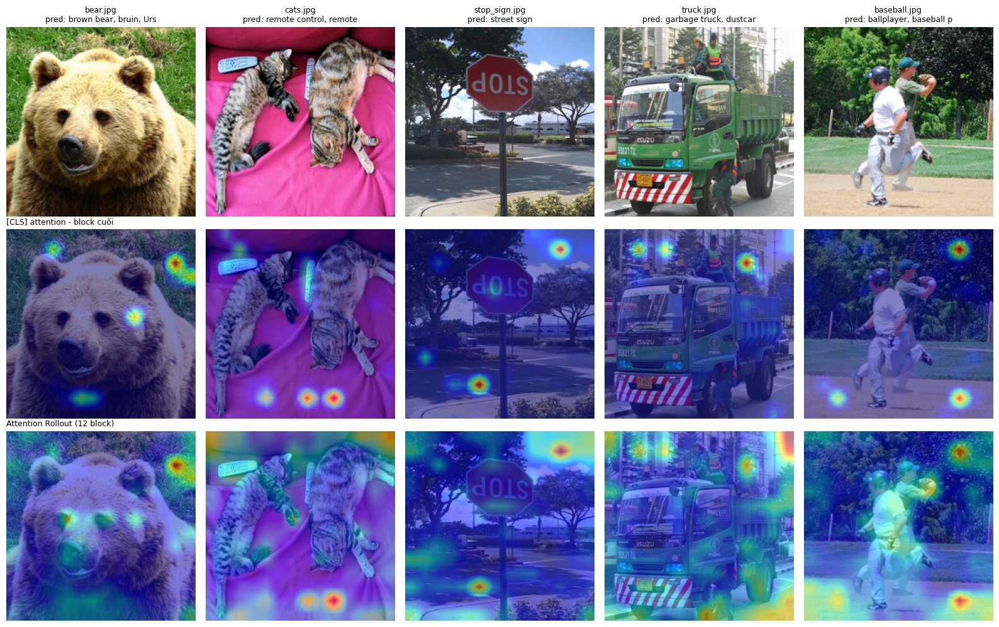

In [19]:
def rollout(attns, discard_ratio=0.0):
    # attns: list (1, h, N, N). Trả về vector 196: mức đóng góp của mỗi patch vào [CLS]
    R = torch.eye(attns[0].shape[-1])
    for A in attns:
        A = A[0].mean(0)                              # trung bình các head
        A = 0.5 * A + 0.5 * torch.eye(A.shape[-1])    # tính nhánh residual
        A = A / A.sum(-1, keepdim=True)
        R = A @ R
    return R[0, 1:]

show = ["bear.jpg", "cats.jpg", "stop_sign.jpg", "truck.jpg", "baseball.jpg"]
fig, axes = plt.subplots(3, len(show), figsize=(3.2 * len(show), 10))
for j, n in enumerate(show):
    top1 = label(LOGITS[n].argmax())
    last = ATT[n][-1][0, :, 0, 1:].mean(0)
    roll = rollout(ATT[n])
    axes[0, j].imshow(imgs[n]); axes[0, j].set_title(f"{n}\npred: {top1[:22]}", fontsize=9)
    axes[1, j].imshow(imgs[n]); axes[1, j].imshow(to_map(last), cmap="jet", alpha=0.5)
    axes[2, j].imshow(imgs[n]); axes[2, j].imshow(to_map(roll), cmap="jet", alpha=0.5)
    for i in range(3):
        axes[i, j].axis("off")
axes[1, 0].set_title("[CLS] attention - block cuối", loc="left", fontsize=9)
axes[2, 0].set_title("Attention Rollout (12 block)", loc="left", fontsize=9)
plt.tight_layout(); save_fig(fig, "08_attention_maps.png"); plt.show()

## 9. Pre-trained và khởi tạo ngẫu nhiên

Cùng kiến trúc ViT-B/16 nhưng `pretrained=False` (trọng số **ngẫu nhiên**, chưa huấn luyện). So sánh dự đoán và entropy của attention `[CLS]`.
Entropy tối đa (attention đều trên 197 token) là $\ln 197 \approx 5.28$.

Pre-trained : [('brown bear, bruin, Ursus arctos', 0.887), ('ice bear, polar bear, Ursus Maritimus, Thalarctos maritimus', 0.001), ('American black bear, black bear, Ursus americanus, Euarctos americanus', 0.001)]
Ngẫu nhiên  : [('parachute, chute', 0.0042), ('junco, snowbird', 0.0037), ('redshank, Tringa totanus', 0.0036)]
Đã lưu: outputs\metrics\cls_entropy_pretrained_vs_random.csv
Đã lưu: outputs\figures\09_pretrained_vs_random.png


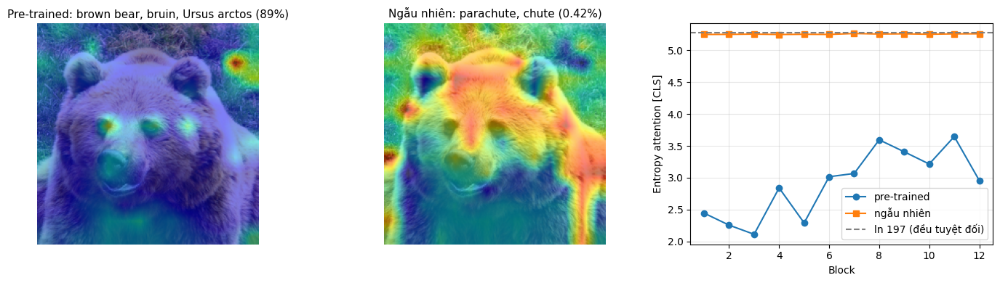

In [20]:
torch.manual_seed(SEED)
model_rand = timm.create_model(MODEL_NAME, pretrained=False).eval().to(DEVICE)   # KHỞI TẠO NGẪU NHIÊN

n = "bear.jpg"
logit_r, att_r = get_attentions(model_rand, to_input(imgs[n]))
pr = logit_r.softmax(-1)[0].topk(3); pp = LOGITS[n].softmax(-1)[0].topk(3)
print("Pre-trained :", [(label(i), round(v.item(), 3)) for v, i in zip(pp.values, pp.indices)])
print("Ngẫu nhiên  :", [(label(i), round(v.item(), 4)) for v, i in zip(pr.values, pr.indices)])

def cls_entropy(attns):
    # entropy của phân phối attention từ [CLS], trung bình các head, cho từng block
    return [float(-(A[0, :, 0] * (A[0, :, 0] + 1e-12).log()).sum(-1).mean()) for A in attns]

ent = pd.DataFrame({"block": range(1, L + 1), "pretrained": cls_entropy(ATT[n]), "random": cls_entropy(att_r)})
save_table(ent, "cls_entropy_pretrained_vs_random.csv")
SUMMARY.update(random_top1_prob=round(pr.values[0].item(), 4), pretrained_top1_prob=round(pp.values[0].item(), 4))

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].imshow(imgs[n]); ax[0].imshow(to_map(rollout(ATT[n])), cmap="jet", alpha=0.5)
ax[0].set_title(f"Pre-trained: {label(pp.indices[0])} ({pp.values[0]:.0%})"); ax[0].axis("off")
ax[1].imshow(imgs[n]); ax[1].imshow(to_map(rollout(att_r)), cmap="jet", alpha=0.5)
ax[1].set_title(f"Ngẫu nhiên: {label(pr.indices[0])[:18]} ({pr.values[0]:.2%})"); ax[1].axis("off")
ax[2].plot(ent.block, ent.pretrained, "o-", label="pre-trained")
ax[2].plot(ent.block, ent.random, "s-", label="ngẫu nhiên")
ax[2].axhline(math.log(N + 1), ls="--", c="gray", label="ln 197 (đều tuyệt đối)")
ax[2].set_xlabel("Block"); ax[2].set_ylabel("Entropy attention [CLS]"); ax[2].legend(); ax[2].grid(alpha=0.3)
plt.tight_layout(); save_fig(fig, "09_pretrained_vs_random.png"); plt.show()

## 10. Attention của ViT tự giám sát (DINO)

`vit_small_patch16_224.dino`: ViT-S/16 (6 head, D=384), **pre-trained** bằng phương pháp tự giám sát DINO (Caron et al., 2021), không dùng nhãn.
Attention `[CLS]` ở block cuối của DINO thường bám theo đường viền đối tượng rõ hơn ViT huấn luyện có nhãn.

Đã lưu: outputs\figures\10_dino_attention.png


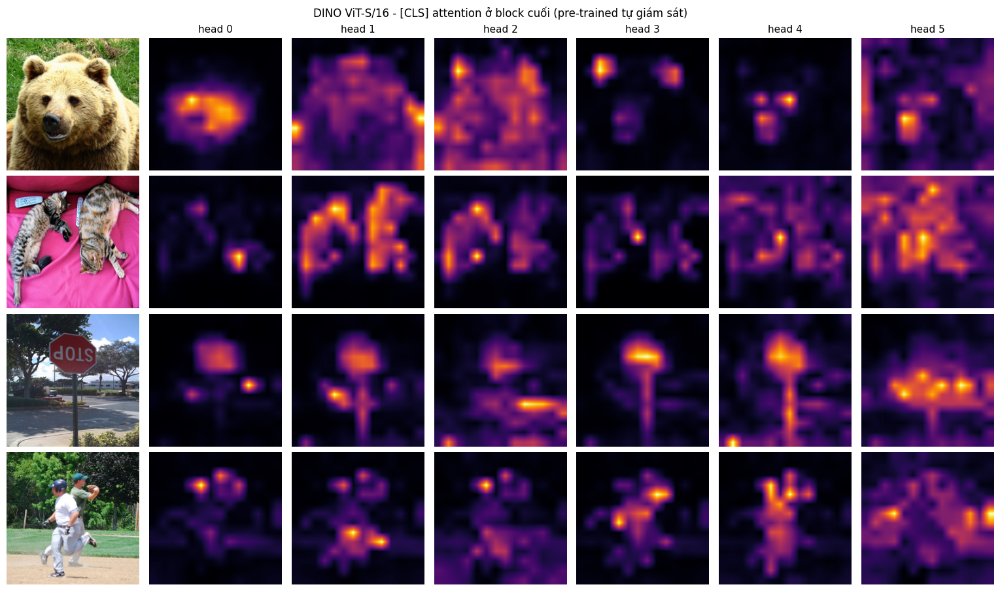

In [21]:
dino = timm.create_model("vit_small_patch16_224.dino", pretrained=True).eval().to(DEVICE)
cfg_d = resolve_data_config({}, model=dino)
norm_d = transforms.Compose([transforms.ToTensor(), transforms.Normalize(cfg_d["mean"], cfg_d["std"])])

show = ["bear.jpg", "cats.jpg", "stop_sign.jpg", "baseball.jpg"]
Hd = dino.blocks[0].attn.num_heads
fig, axes = plt.subplots(len(show), Hd + 1, figsize=(2.2 * (Hd + 1), 2.3 * len(show)))
for i, n in enumerate(show):
    _, att_d = get_attentions(dino, norm_d(imgs[n]).unsqueeze(0).to(DEVICE))
    a = att_d[-1][0, :, 0, 1:]                       # (6, 196)
    axes[i, 0].imshow(imgs[n]); axes[i, 0].axis("off")
    for hh in range(Hd):
        axes[i, hh + 1].imshow(to_map(a[hh]), cmap="inferno"); axes[i, hh + 1].axis("off")
        if i == 0:
            axes[i, hh + 1].set_title(f"head {hh}")
plt.suptitle("DINO ViT-S/16 - [CLS] attention ở block cuối (pre-trained tự giám sát)")
plt.tight_layout(); save_fig(fig, "10_dino_attention.png"); plt.show()

## 11. Vai trò của Positional Embedding: thí nghiệm nhanh

Self-Attention không phụ thuộc thứ tự đầu vào (permutation-equivariant). Nếu bỏ $\mathbf{E}_{pos}$, mô hình chỉ thấy một "túi patch".
4 trường hợp trên mô hình pre-trained (không huấn luyện lại):
1. Gốc
2. Xáo trộn vị trí các patch (giữ $\mathbf{E}_{pos}$) → giống ảnh bị cắt ghép lộn xộn
3. Bỏ $\mathbf{E}_{pos}$ (đặt bằng 0)
4. Bỏ $\mathbf{E}_{pos}$ **và** xáo trộn patch → kết quả phải **giống hệt** trường hợp 3

Lưu ý: đây là bỏ $\mathbf{E}_{pos}$ trên mô hình đã học với nó, nên giảm mạnh. Paper gốc (Phụ lục D.4) huấn luyện lại không có $\mathbf{E}_{pos}$ thì độ chính xác 5-shot ImageNet chỉ giảm từ 64.2% xuống 61.4%.

In [22]:
def forward_custom(m, x, use_pos=True, perm=None):
    t = m.patch_embed(x)                                        # (B, 196, D)
    if perm is not None:
        t = t[:, perm]                                          # xáo trộn thứ tự patch
    t = torch.cat([m.cls_token.expand(t.shape[0], -1, -1), t], dim=1)
    if use_pos:
        t = t + m.pos_embed
    t = m.norm(m.blocks(t))
    return m.forward_head(t)

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(N, generator=g)
rows = []
for n in imgs:
    x = to_input(imgs[n])
    base = forward_custom(model, x)
    c0 = int(base.argmax())
    outs = {"1. Gốc": base,
            "2. Xáo trộn patch": forward_custom(model, x, perm=perm),
            "3. Bỏ pos": forward_custom(model, x, use_pos=False),
            "4. Bỏ pos + xáo trộn": forward_custom(model, x, use_pos=False, perm=perm)}
    diff34 = (outs["3. Bỏ pos"] - outs["4. Bỏ pos + xáo trộn"]).abs().max().item()
    for case, o in outs.items():
        pr_ = o.softmax(-1)[0]
        rows.append((n, case, label(o.argmax()), round(pr_[c0].item(), 4), int(o.argmax()) == c0, diff34))
df_pos = pd.DataFrame(rows, columns=["image", "case", "top1", "prob_lớp_gốc", "giữ_top1", "max|logit3-logit4|"])
save_table(df_pos, "ablation_position.csv")
print("Sai khác tối đa giữa TH3 và TH4:", df_pos["max|logit3-logit4|"].max())
SUMMARY["pos_ablation_keep_top1"] = df_pos.groupby("case")["giữ_top1"].sum().to_dict()
df_pos.pivot(index="image", columns="case", values="prob_lớp_gốc")

Đã lưu: outputs\metrics\ablation_position.csv
Sai khác tối đa giữa TH3 và TH4: 5.841255187988281e-06


case,1. Gốc,2. Xáo trộn patch,3. Bỏ pos,4. Bỏ pos + xáo trộn
image,,,,
baseball.jpg,0.6996,0.5905,0.0257,0.0257
bear.jpg,0.8868,0.6526,0.0021,0.0021
cats.jpg,0.3740,0.0004,0.0002,0.0002
kitchen.jpg,0.3798,0.0005,0.0007,0.0007
stop_sign.jpg,0.8195,0.2877,0.0003,0.0003
truck.jpg,0.8889,0.0291,0.0151,0.0151


Đã lưu: outputs\figures\11_position_ablation.png


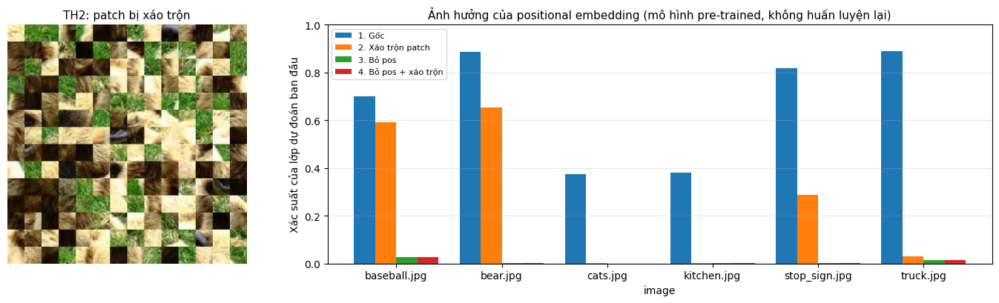

In [23]:
pv = df_pos.pivot(index="image", columns="case", values="prob_lớp_gốc")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 2.2]})
# ảnh gấu sau khi xáo trộn patch
img = np.array(imgs["bear.jpg"]); sh = np.zeros_like(img)
for new, old in enumerate(perm.tolist()):
    r0, c0_ = divmod(old, 14); r1, c1 = divmod(new, 14)
    sh[r1*P:(r1+1)*P, c1*P:(c1+1)*P] = img[r0*P:(r0+1)*P, c0_*P:(c0_+1)*P]
ax[0].imshow(sh); ax[0].set_title("TH2: patch bị xáo trộn"); ax[0].axis("off")
pv.plot.bar(ax=ax[1], rot=0, width=0.8)
ax[1].set_ylabel("Xác suất của lớp dự đoán ban đầu"); ax[1].set_ylim(0, 1); ax[1].grid(axis="y", alpha=0.3)
ax[1].set_title("Ảnh hưởng của positional embedding (mô hình pre-trained, không huấn luyện lại)")
ax[1].legend(fontsize=8)
plt.tight_layout(); save_fig(fig, "11_position_ablation.png"); plt.show()

## 12. So sánh ViT-B/16 và ResNet-50

Cả hai đều **pre-trained**. Đếm tham số, số phép nhân-cộng (GMACs, đếm bằng `torch.utils.flop_counter`) và thời gian suy luận trên máy đang chạy (batch = 1).

In [24]:
from torch.utils.flop_counter import FlopCounterMode

resnet = timm.create_model("resnet50.a1_in1k", pretrained=True).eval().to(DEVICE)
cfg_r = resolve_data_config({}, model=resnet)
norm_r = transforms.Compose([transforms.ToTensor(), transforms.Normalize(cfg_r["mean"], cfg_r["std"])])

def gmacs(m, x):
    with FlopCounterMode(display=False) as fc:
        m(x)
    return fc.get_total_flops() / 2 / 1e9            # FLOPs = 2 x MACs

def latency_ms(m, x, runs=10):
    for _ in range(3):
        m(x)                                         # khởi động
    t = time.perf_counter()
    for _ in range(runs):
        m(x)
    return (time.perf_counter() - t) / runs * 1000

rows = []
for nm, m, nf in [("ViT-B/16", model, normalize), ("ResNet-50", resnet, norm_r)]:
    x = nf(imgs["bear.jpg"]).unsqueeze(0).to(DEVICE)
    preds = [label(m(nf(imgs[n]).unsqueeze(0).to(DEVICE)).argmax()) for n in imgs]
    rows.append((nm, round(sum(p.numel() for p in m.parameters()) / 1e6, 1), round(gmacs(m, x), 2),
                 round(latency_ms(m, x), 1), "; ".join(preds)))
df_cmp = pd.DataFrame(rows, columns=["model", "params_M", "GMACs", f"latency_ms_{DEVICE}", "top1_6_ảnh"])
save_table(df_cmp, "vit_vs_resnet50.csv")
SUMMARY["vit_vs_resnet"] = df_cmp.drop(columns="top1_6_ảnh").to_dict(orient="records")
df_cmp

Đã lưu: outputs\metrics\vit_vs_resnet50.csv


,model,params_M,GMACs,latency_ms_cpu,top1_6_ảnh
0,ViT-B/16,86.6,16.85,147.7,"brown bear, bruin, Ursus arctos; remote contro..."
1,ResNet-50,25.6,4.09,56.0,"brown bear, bruin, Ursus arctos; tiger cat; st..."


## 13. Độ phức tạp $O(N^2)$ theo độ phân giải

Chi phí (số phép nhân-cộng) của 1 khối encoder với $N$ token, chiều $D$:
- Các lớp Linear (qkv, proj, MLP): $12ND^2$ → tăng **tuyến tính** theo $N$
- Tính $QK^\top$ và $AV$: $2N^2D$ → tăng **bậc hai** theo $N$
- Bộ nhớ ma trận attention mỗi khối: $h \cdot N^2$ phần tử

Đo thực tế thời gian suy luận khi tăng kích thước ảnh (mô hình khởi tạo ngẫu nhiên, chỉ dùng để đo thời gian), so với ResNet-50.

In [25]:
sizes = [224, 320, 384, 448, 512]
rows = []
for s in sizes:
    n_tok = (s // P) ** 2 + 1
    vit_s = timm.create_model(MODEL_NAME, pretrained=False, img_size=s).eval().to(DEVICE)
    x = torch.randn(1, 3, s, s, device=DEVICE)
    rows.append(dict(img_size=s, tokens=n_tok,
                     linear_GMACs=L * 12 * n_tok * D * D / 1e9,
                     attn_matrix_GMACs=L * 2 * n_tok ** 2 * D / 1e9,
                     attn_mem_MB_per_block=H * n_tok ** 2 * 4 / 2 ** 20,
                     vit_ms=latency_ms(vit_s, x, runs=3),
                     resnet50_ms=latency_ms(resnet, x, runs=3)))
    del vit_s
df_cx = pd.DataFrame(rows).round(2)
save_table(df_cx, "complexity_vs_resolution.csv")
SUMMARY["complexity"] = df_cx.to_dict(orient="records")
df_cx

Đã lưu: outputs\metrics\complexity_vs_resolution.csv


,img_size,tokens,linear_GMACs,attn_matrix_GMACs,attn_mem_MB_per_block,vit_ms,resnet50_ms
0,224,197,16.73,0.72,1.78,167.45,58.70
1,320,401,34.06,2.96,7.36,281.15,96.53
2,384,577,49.01,6.14,15.24,409.78,132.43
3,448,785,66.67,11.36,28.21,564.93,171.66
4,512,1025,87.06,19.37,48.09,760.56,221.89


Đã lưu: outputs\figures\13_complexity.png


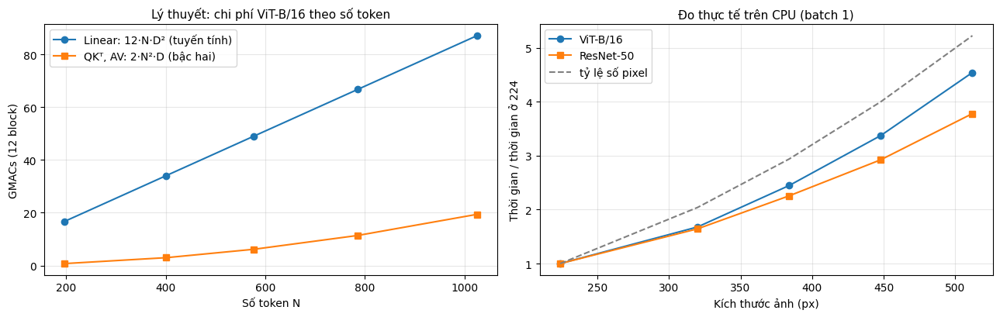

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(df_cx.tokens, df_cx.linear_GMACs, "o-", label="Linear: 12·N·D² (tuyến tính)")
ax[0].plot(df_cx.tokens, df_cx.attn_matrix_GMACs, "s-", label="QKᵀ, AV: 2·N²·D (bậc hai)")
ax[0].set_xlabel("Số token N"); ax[0].set_ylabel("GMACs (12 block)"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[0].set_title("Lý thuyết: chi phí ViT-B/16 theo số token")
ax[1].plot(df_cx.img_size, df_cx.vit_ms / df_cx.vit_ms[0], "o-", label="ViT-B/16")
ax[1].plot(df_cx.img_size, df_cx.resnet50_ms / df_cx.resnet50_ms[0], "s-", label="ResNet-50")
ax[1].plot(df_cx.img_size, (df_cx.img_size / 224) ** 2, "--", c="gray", label="tỷ lệ số pixel")
ax[1].set_xlabel("Kích thước ảnh (px)"); ax[1].set_ylabel("Thời gian / thời gian ở 224")
ax[1].set_title(f"Đo thực tế trên {DEVICE.upper()} (batch 1)"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); save_fig(fig, "13_complexity.png"); plt.show()

## 14. Tổng kết số liệu và nhận xét

In [27]:
with open(MET_DIR / "summary.json", "w", encoding="utf-8") as f:
    json.dump(SUMMARY, f, ensure_ascii=False, indent=2)
print("Đã lưu:", (MET_DIR / "summary.json").relative_to(ROOT))
print(json.dumps(SUMMARY, ensure_ascii=False, indent=2))

Đã lưu: outputs\metrics\summary.json
{
  "model": "vit_base_patch16_224.augreg2_in21k_ft_in1k",
  "weights": "pretrained (IN-21k -> IN-1k)",
  "patch": 16,
  "dim": 768,
  "depth": 12,
  "heads": 12,
  "num_patches": 196,
  "params_M": 86.57,
  "attn_dist_block1_min": 13.6,
  "attn_dist_block1_max": 121.2,
  "attn_dist_last_mean": 120.1,
  "random_top1_prob": 0.0042,
  "pretrained_top1_prob": 0.8868,
  "pos_ablation_keep_top1": {
    "1. Gốc": 6,
    "2. Xáo trộn patch": 2,
    "3. Bỏ pos": 0,
    "4. Bỏ pos + xáo trộn": 0
  },
  "vit_vs_resnet": [
    {
      "model": "ViT-B/16",
      "params_M": 86.6,
      "GMACs": 16.85,
      "latency_ms_cpu": 147.7
    },
    {
      "model": "ResNet-50",
      "params_M": 25.6,
      "GMACs": 4.09,
      "latency_ms_cpu": 56.0
    }
  ],
  "complexity": [
    {
      "img_size": 224,
      "tokens": 197,
      "linear_GMACs": 16.73,
      "attn_matrix_GMACs": 0.72,
      "attn_mem_MB_per_block": 1.78,
      "vit_ms": 167.45,
      "resnet50_ms"

**Nhận xét từ demo**

- Các bước tính tay (patch embedding, Self-Attention, khối encoder) cho kết quả trùng với `timm` (sai khác ~1e-5, do làm tròn số thực), xác nhận công thức và kích thước tensor $(3,224,224) \to (196,768) \to (197,768) \to (768) \to (1000)$.
- Positional embedding đã học có cấu trúc 2D theo hàng/cột dù được khai báo dạng 1D.
- Ở block đầu, một số head đã có khoảng cách attention lớn (nhìn toàn cục), số khác nhỏ (giống tích chập cục bộ). Càng sâu, khoảng cách trung bình càng lớn.
- Attention Map của mô hình pre-trained tập trung vào đối tượng; mô hình khởi tạo ngẫu nhiên cho attention gần như đều và dự đoán vô nghĩa (xác suất ~0.1% = 1/1000).
- Bỏ positional embedding thì đầu ra không đổi khi xáo trộn patch: mô hình mất thông tin không gian.
- ViT-B/16 có nhiều tham số và phép tính hơn ResNet-50 ở cùng độ phân giải 224. Khi tăng độ phân giải, phần $2N^2D$ tăng nhanh hơn số pixel.

**Hạn chế của ViT**
- Chi phí attention $O(N^2)$ theo số token → khó dùng cho ảnh độ phân giải cao, dense prediction (Swin dùng window attention để giảm về tuyến tính).
- Ít inductive bias → cần dữ liệu pre-train lớn (ImageNet-21k, JFT-300M) hoặc kỹ thuật huấn luyện/augmentation mạnh (DeiT).
- Attention map chỉ là một cách giải thích gần đúng, không phải giải thích đầy đủ cho quyết định của mô hình.

## Tài liệu tham khảo
1. Dosovitskiy, A. et al. (2020). *An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale*. ICLR 2021. arXiv:2010.11929
2. Vaswani, A. et al. (2017). *Attention Is All You Need*. NeurIPS. arXiv:1706.03762
3. Touvron, H. et al. (2021). *Training data-efficient image transformers & distillation through attention* (DeiT). ICML. arXiv:2012.12877
4. Liu, Z. et al. (2021). *Swin Transformer: Hierarchical Vision Transformer using Shifted Windows*. ICCV. arXiv:2103.14030
5. Steiner, A. et al. (2021). *How to train your ViT? Data, Augmentation, and Regularization in Vision Transformers*. arXiv:2106.10270
6. Caron, M. et al. (2021). *Emerging Properties in Self-Supervised Vision Transformers* (DINO). ICCV. arXiv:2104.14294
7. Abnar, S. & Zuidema, W. (2020). *Quantifying Attention Flow in Transformers* (Attention Rollout). ACL. arXiv:2005.00928
8. He, K. et al. (2016). *Deep Residual Learning for Image Recognition*. CVPR. arXiv:1512.03385
9. Wightman, R. *PyTorch Image Models (timm)*. https://github.com/huggingface/pytorch-image-models
10. Lin, T.-Y. et al. (2014). *Microsoft COCO: Common Objects in Context* (ảnh mẫu). arXiv:1405.0312